# LAB 03 — PHÂN CỤM KHÁCH HÀNG (CUSTOMER SEGMENTATION)

**Môn học:** Máy học (Machine Learning)  
**Phương pháp:** Học máy không giám sát (*Unsupervised Learning*)  
**Thuật toán chính:** K-means được cài đặt bằng NumPy  
**Dữ liệu:** Customer Segmentation — các thuộc tính tuổi, thu nhập hằng năm, điểm chi tiêu và giới tính.

Notebook này được trình bày theo quy trình báo cáo thực nghiệm: xác định bài toán → nạp dữ liệu → EDA → tiền xử lý → xây dựng thuật toán → thử nghiệm tham số → đánh giá → diễn giải cụm → thử phân cụm khách hàng mới → kết luận. Dữ liệu CSV được đóng gói bên trong notebook để có thể chạy độc lập mà không cần tải lại file dữ liệu.

## Step 0 — Định nghĩa bài toán và chiến lược đánh giá

### 0.1. Bối cảnh

Doanh nghiệp muốn hiểu các nhóm khách hàng khác nhau để có thể thiết kế chương trình chăm sóc, ưu đãi hoặc tiếp thị phù hợp. Nếu chỉ nhìn từng khách hàng riêng lẻ, việc nhận diện các kiểu hành vi tổng quát sẽ khó khăn. Phân cụm giúp gom những khách hàng có đặc điểm tương tự vào cùng một nhóm.

### 0.2. Mục tiêu

- Khám phá các nhóm khách hàng dựa trên **Age**, **Annual Income** và **Spending Score**.
- Tự cài đặt K-means bằng NumPy để hiểu cơ chế gán điểm vào cụm và cập nhật tâm cụm.
- Thử nhiều giá trị `K`, sau đó kết hợp **Inertia / Elbow Method** và **Silhouette Score** để lựa chọn số cụm hợp lý.
- Mô tả từng cụm bằng thống kê tuổi, thu nhập, điểm chi tiêu và tỷ lệ giới tính.

### 0.3. Vì sao đây là học không giám sát?

Bộ dữ liệu không có cột nhãn mục tiêu đúng/sai được cung cấp sẵn. K-means tự tạo nhãn cụm như `0, 1, 2, ...` sau khi học cấu trúc dữ liệu. Các số này chỉ là **mã định danh cụm**, không phải thứ hạng và cũng không phải nhãn 0/1 có sẵn.

### 0.4. Đặc trưng sử dụng

| Cột | Vai trò | Cách dùng |
|---|---|---|
| `Customer ID` | Mã định danh khách hàng | Không đưa vào tính khoảng cách |
| `Age` | Tuổi | Đặc trưng phân cụm |
| `Annual Income` | Thu nhập hằng năm | Đặc trưng phân cụm |
| `Spending Score` | Điểm chi tiêu | Đặc trưng phân cụm |
| `Gender` | Giới tính | Dùng để mô tả cụm sau khi phân cụm, không dùng để tính khoảng cách |

### 0.5. Chiến lược đánh giá

- **Inertia:** tổng bình phương khoảng cách từ mỗi điểm tới tâm cụm tương ứng; thường giảm khi tăng `K`, vì vậy không nên dùng riêng chỉ số này để chọn `K`.
- **Elbow Method:** tìm vùng mà mức giảm Inertia bắt đầu chậm lại.
- **Silhouette Score:** đánh giá độ gần của điểm với cụm của nó so với cụm gần nhất khác. Giá trị càng cao thường cho thấy cụm tách biệt tốt hơn; giá trị gần 0 cho thấy cụm có thể chồng lấn.
- **Diễn giải nghiệp vụ:** kiểm tra số lượng khách hàng và giá trị trung bình của các đặc trưng trong từng cụm.

> Lưu ý: Silhouette được tính trên một mẫu ngẫu nhiên cố định để giảm thời gian chạy. Kết quả là ước lượng trên mẫu, không phải chứng minh tuyệt đối rằng số cụm được chọn là tối ưu trong mọi khía cạnh.

## Step 1 — Khai báo thư viện và cấu hình

Sử dụng `pandas` để thao tác bảng dữ liệu, `NumPy` để tính toán ma trận, `matplotlib` và `seaborn` để trực quan hóa. Thuật toán K-means ở phần sau được tự cài đặt, không gọi `sklearn.cluster.KMeans`.

In [1]:
import os
import gzip
import base64
import io
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Các thư viện đã sẵn sàng.")

NumPy: 2.2.6
Pandas: 2.3.2
Các thư viện đã sẵn sàng.


## Step 2 — Nạp dữ liệu

Notebook có một bản dữ liệu CSV nén kèm theo. Đoạn mã sẽ giải nén dữ liệu vào bộ nhớ và đọc bằng `pandas`, vì vậy không cần cấu hình đường dẫn bên ngoài. Nếu muốn dùng một file CSV khác, có thể thay `df_raw = pd.read_csv(...)` bằng đường dẫn tới file của nhóm.

In [2]:
# Dữ liệu được nén gzip và mã hóa Base64 để notebook có thể chạy độc lập.
# Không cần sửa đoạn này khi chạy notebook.
DATA_B64 = r'''...'''
csv_bytes = gzip.decompress(base64.b64decode(DATA_B64))
df_raw = pd.read_csv(io.BytesIO(csv_bytes))

print("Kích thước dữ liệu:", df_raw.shape)
print("Số dòng:", len(df_raw))
print("Số cột:", len(df_raw.columns))
display(df_raw.head())

Kích thước dữ liệu: (15079, 5)
Số dòng: 15079
Số cột: 5


,Customer ID,Age,Gender,Annual Income,Spending Score
0,d410ea53-6661-42a9-ad3a-f554b05fd2a7,30,Male,151479,89
1,1770b26f-493f-46b6-837f-4237fb5a314e,58,Female,185088,95
2,e81aa8eb-1767-4b77-87ce-1620dc732c5e,62,Female,70912,76
3,9795712a-ad19-47bf-8886-4f997d6046e3,23,Male,55460,57
4,64139426-2226-4cd6-bf09-91bce4b4db5e,24,Male,153752,76


## Step 3 — Khám phá dữ liệu (Exploratory Data Analysis — EDA)

### 3.1. Ý nghĩa và kiểu dữ liệu

Trước khi huấn luyện, cần xem tên cột, kiểu dữ liệu và một số dòng đầu để hiểu mỗi bản ghi biểu diễn điều gì. Bước này giúp phát hiện sai tên cột hoặc kiểu dữ liệu không phù hợp.

In [3]:
print("THÔNG TIN CẤU TRÚC DỮ LIỆU")
df_raw.info()
print("\nKiểu dữ liệu từng cột:")
display(df_raw.dtypes.rename("dtype").to_frame())
print("\nNăm dòng đầu:")
display(df_raw.head())
print("\nNăm dòng cuối:")
display(df_raw.tail())

THÔNG TIN CẤU TRÚC DỮ LIỆU
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15079 entries, 0 to 15078
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customer ID     15079 non-null  object
 1   Age             15079 non-null  int64 
 2   Gender          15079 non-null  object
 3   Annual Income   15079 non-null  int64 
 4   Spending Score  15079 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 589.2+ KB

Kiểu dữ liệu từng cột:


,dtype
Customer ID,object
Age,int64
Gender,object
Annual Income,int64
Spending Score,int64



Năm dòng đầu:


,Customer ID,Age,Gender,Annual Income,Spending Score
0,d410ea53-6661-42a9-ad3a-f554b05fd2a7,30,Male,151479,89
1,1770b26f-493f-46b6-837f-4237fb5a314e,58,Female,185088,95
2,e81aa8eb-1767-4b77-87ce-1620dc732c5e,62,Female,70912,76
3,9795712a-ad19-47bf-8886-4f997d6046e3,23,Male,55460,57
4,64139426-2226-4cd6-bf09-91bce4b4db5e,24,Male,153752,76



Năm dòng cuối:


,Customer ID,Age,Gender,Annual Income,Spending Score
15074,a0504768-a85f-4930-ac24-55bc8e4fec9e,29,Female,97723,30
15075,a08c4e0e-d1fe-48e7-9366-aab11ae409cd,22,Male,73361,74
15076,0e87c25a-268c-401a-8ba1-7111dcde6f1a,18,Female,112337,48
15077,5f388cbe-3373-4e16-b743-38f508f2249f,26,Female,94312,5
15078,b8b8f561-ebca-4401-8afe-544c906554ba,19,Male,78045,2


### 3.2. Giá trị thiếu, bản ghi trùng và thống kê mô tả

- `isna().sum()` cho biết số giá trị thiếu theo cột.
- `duplicated().sum()` kiểm tra các dòng trùng hoàn toàn.
- `describe()` tóm tắt số lượng, trung bình, độ lệch chuẩn, min, các tứ phân vị và max.

Không nên tự động xóa ngoại lệ chỉ vì một điểm nằm xa phần lớn dữ liệu. Cần kiểm tra xem đó là lỗi nhập liệu hay là khách hàng có đặc điểm thực sự khác biệt.

In [4]:
print("SỐ GIÁ TRỊ THIẾU THEO CỘT")
display(df_raw.isna().sum().rename("missing_count").to_frame())
print("Số dòng trùng hoàn toàn:", int(df_raw.duplicated().sum()))

numeric_cols = ["Age", "Annual Income", "Spending Score"]
print("\nTHỐNG KÊ MÔ TẢ CÁC ĐẶC TRƯNG SỐ")
display(df_raw[numeric_cols].describe().T.round(2))

print("\nSỐ LƯỢNG THEO GIỚI TÍNH")
if "Gender" in df_raw.columns:
    display(df_raw["Gender"].value_counts(dropna=False).rename_axis("Gender").to_frame("Count"))

SỐ GIÁ TRỊ THIẾU THEO CỘT


,missing_count
Customer ID,0
Age,0
Gender,0
Annual Income,0
Spending Score,0


Số dòng trùng hoàn toàn: 0

THỐNG KÊ MÔ TẢ CÁC ĐẶC TRƯNG SỐ


,count,mean,std,min,25%,50%,75%,max
Age,15079.0,54.19,21.12,18.0,36.0,54.0,72.0,90.0
Annual Income,15079.0,109742.88,52249.43,20022.0,64141.0,109190.0,155008.0,199974.0
Spending Score,15079.0,50.59,28.73,1.0,26.0,51.0,75.0,100.0



SỐ LƯỢNG THEO GIỚI TÍNH


,Count
Gender,
Male,7595
Female,7484


### 3.3. Phân phối đặc trưng và ngoại lệ

Histogram giúp quan sát phân phối của từng biến; boxplot cho thấy trung vị, khoảng tứ phân vị và các điểm có khả năng là ngoại lệ theo quy tắc 1.5 × IQR. Phần này chỉ **phát hiện và báo cáo**, không tự động loại bỏ dữ liệu.

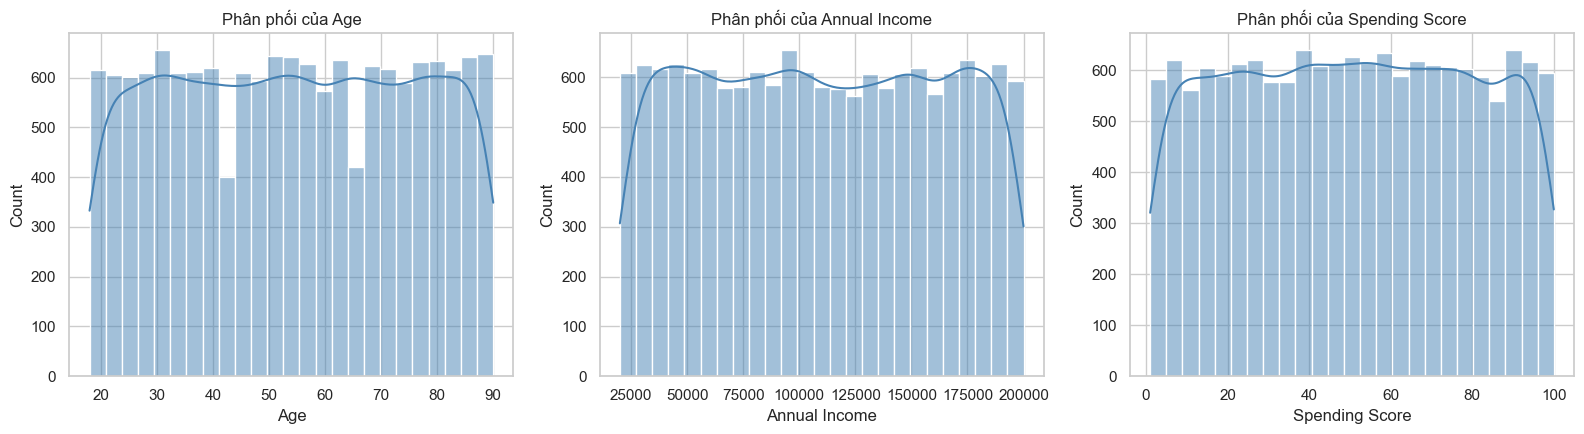

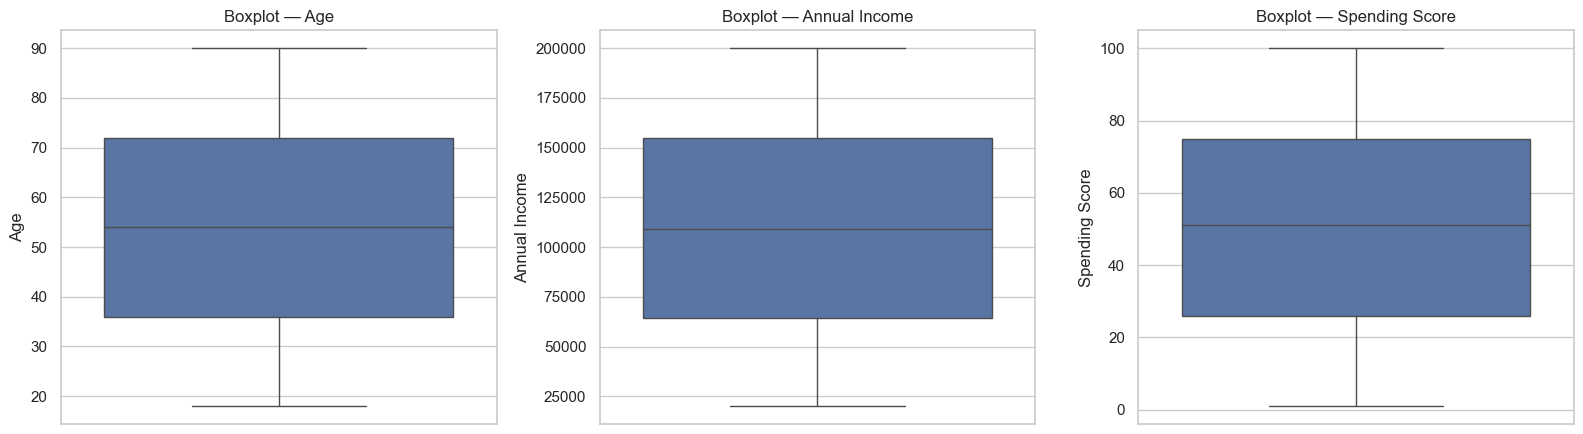

BẢNG KIỂM TRA NGOẠI LỆ THEO IQR


,Feature,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier percent
0,Age,36.0,72.0,36.0,-18.0,126.0,0,0.0
1,Annual Income,64141.0,155008.0,90867.0,-72159.5,291308.5,0,0.0
2,Spending Score,26.0,75.0,49.0,-47.5,148.5,0,0.0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df_raw, x=col, kde=True, color="steelblue", ax=ax)
    ax.set_title(f"Phân phối của {col}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
outlier_rows = []
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df_raw, y=col, ax=ax)
    ax.set_title(f"Boxplot — {col}")
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df_raw[col] < lower) | (df_raw[col] > upper)).sum())
    outlier_rows.append({"Feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "Lower bound": lower, "Upper bound": upper,
                         "Outlier count": count, "Outlier percent": 100 * count / len(df_raw)})
plt.tight_layout()
plt.show()
print("BẢNG KIỂM TRA NGOẠI LỆ THEO IQR")
display(pd.DataFrame(outlier_rows).round(2))

### 3.4. Quan sát mối quan hệ giữa các đặc trưng

Các biểu đồ phân tán giúp xem hai biến thay đổi cùng nhau như thế nào. Màu sắc theo giới tính chỉ phục vụ quan sát dữ liệu ban đầu; `Gender` vẫn không được đưa vào mô hình K-means trong notebook này.

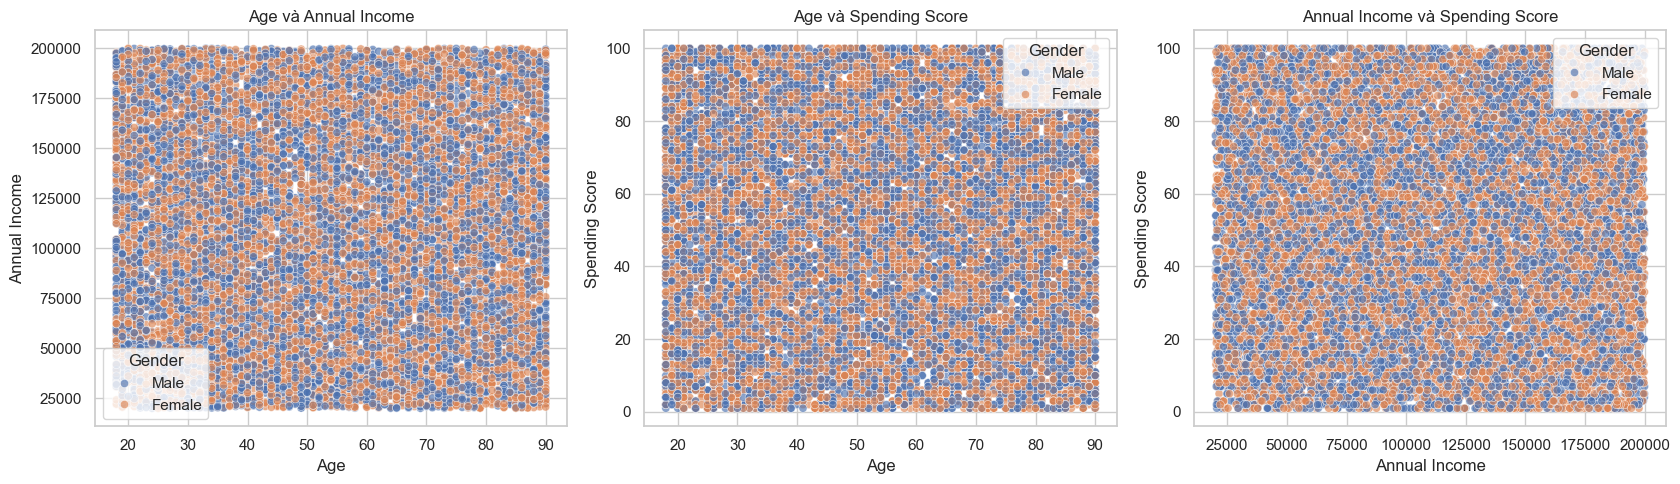

In [6]:
pairs = [("Age", "Annual Income"), ("Age", "Spending Score"),
         ("Annual Income", "Spending Score")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (x_col, y_col) in zip(axes, pairs):
    sns.scatterplot(data=df_raw, x=x_col, y=y_col, hue="Gender" if "Gender" in df_raw.columns else None,
                    alpha=0.65, s=35, ax=ax)
    ax.set_title(f"{x_col} và {y_col}")
plt.tight_layout()
plt.show()

## Step 4 — Tiền xử lý và chuẩn hóa đặc trưng

### 4.1. Làm sạch dữ liệu

Các bước gồm: kiểm tra cột bắt buộc, loại dòng trùng hoàn toàn, chuyển ba đặc trưng sang kiểu số, loại dòng thiếu giá trị ở các cột cần thiết và loại giá trị vô hạn. `Customer ID` và `Gender` được giữ lại để nhận diện/mô tả khách hàng, nhưng không tham gia tính khoảng cách.

### 4.2. Vì sao phải chuẩn hóa?

K-means dựa trên khoảng cách Euclid. Nếu một biến có thang đo lớn hơn hẳn biến khác, biến đó có thể chi phối khoảng cách. Chuẩn hóa Z-score đưa mỗi đặc trưng về trung bình gần 0 và độ lệch chuẩn gần 1:

\[
z = \frac{x - \mu}{\sigma}
\]

Trong đó \(\mu\) là trung bình và \(\sigma\) là độ lệch chuẩn của đặc trưng. Với dữ liệu hiện tại, chuẩn hóa được tính trên toàn bộ tập dùng cho phân cụm vì đây là bài toán khám phá không có nhãn mục tiêu để chia train/test theo cách học có giám sát.

In [7]:
required_cols = ["Customer ID", "Age", "Gender", "Annual Income", "Spending Score"]
missing_cols = [col for col in required_cols if col not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Thiếu cột bắt buộc: {missing_cols}")

n_before = len(df_raw)
df = df_raw[required_cols].copy()
df = df.drop_duplicates().copy()
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["Gender"] = df["Gender"].astype("string").str.strip().str.title()
df = df.dropna(subset=required_cols).copy()
finite_mask = np.isfinite(df[numeric_cols].to_numpy(dtype=float)).all(axis=1)
df = df.loc[finite_mask].copy()
if df.empty:
    raise ValueError("Không còn dữ liệu hợp lệ sau khi làm sạch.")

print("Số dòng trước làm sạch:", n_before)
print("Số dòng sau làm sạch:", len(df))
print("Số dòng bị loại:", n_before - len(df))
display(df.head())

Số dòng trước làm sạch: 15079
Số dòng sau làm sạch: 15079
Số dòng bị loại: 0


,Customer ID,Age,Gender,Annual Income,Spending Score
0,d410ea53-6661-42a9-ad3a-f554b05fd2a7,30,Male,151479,89
1,1770b26f-493f-46b6-837f-4237fb5a314e,58,Female,185088,95
2,e81aa8eb-1767-4b77-87ce-1620dc732c5e,62,Female,70912,76
3,9795712a-ad19-47bf-8886-4f997d6046e3,23,Male,55460,57
4,64139426-2226-4cd6-bf09-91bce4b4db5e,24,Male,153752,76


In [8]:
feature_cols = ["Age", "Annual Income", "Spending Score"]
means = df[feature_cols].mean()
stds = df[feature_cols].std(ddof=0).replace(0, 1)
X_scaled_df = (df[feature_cols] - means) / stds
X = X_scaled_df.to_numpy(dtype=float)

scaling_table = pd.DataFrame({"Mean trước chuẩn hóa": means,
                               "Std trước chuẩn hóa": stds,
                               "Mean sau chuẩn hóa": X_scaled_df.mean(),
                               "Std sau chuẩn hóa": X_scaled_df.std(ddof=0)})
print("THÔNG SỐ CHUẨN HÓA")
display(scaling_table.round(4))
print("Kích thước ma trận X:", X.shape)
print("Ví dụ 5 dòng đã chuẩn hóa:")
display(X_scaled_df.head().round(3))

THÔNG SỐ CHUẨN HÓA


,Mean trước chuẩn hóa,Std trước chuẩn hóa,Mean sau chuẩn hóa,Std sau chuẩn hóa
Age,54.1916,21.1185,-0.0,1.0
Annual Income,109742.8806,52247.6933,-0.0,1.0
Spending Score,50.5916,28.7260,-0.0,1.0


Kích thước ma trận X: (15079, 3)
Ví dụ 5 dòng đã chuẩn hóa:


,Age,Annual Income,Spending Score
0,-1.146,0.799,1.337
1,0.180,1.442,1.546
2,0.370,-0.743,0.885
3,-1.477,-1.039,0.223
4,-1.430,0.842,0.885


## Step 5 — Xây dựng thuật toán K-means từ đầu

### 5.1. Nguyên lý hoạt động

K-means chia dữ liệu thành `K` cụm bằng cách lặp hai bước chính:

1. **Gán cụm (Assignment):** với mỗi điểm dữ liệu, tính khoảng cách tới các tâm cụm và gán điểm vào tâm gần nhất.
2. **Cập nhật tâm (Update):** tính trung bình các điểm thuộc từng cụm để tạo tâm mới.

Lặp lại cho tới khi tâm cụm không còn thay đổi đáng kể hoặc đạt số vòng lặp tối đa.

### 5.2. Hàm mục tiêu

\[
J = \sum_{i=1}^{n} \left\|x_i - \mu_{c_i}\right\|^2
\]

Trong đó \(x_i\) là điểm dữ liệu, \(\mu_{c_i}\) là tâm của cụm mà điểm \(i\) được gán vào. Đại lượng này chính là **Inertia**.

### 5.3. Mã giả

```text
Chọn ngẫu nhiên K điểm làm tâm ban đầu
Lặp tối đa max_iter lần:
    Tính khoảng cách từ mỗi điểm đến từng tâm
    Gán mỗi điểm vào tâm gần nhất
    Tính trung bình các điểm trong mỗi cụm để cập nhật tâm
    Nếu tâm gần như không đổi thì dừng
Tính Inertia và trả về nhãn cụm, tâm cụm
```

**Điểm cần lưu ý:** K-means có thể hội tụ về nghiệm khác nhau tùy tâm ban đầu. Vì vậy notebook cố định `random_state=42` để kết quả có thể tái lập.

In [9]:
# Dùng chung một cài đặt K-means trong src/ để notebook và pipeline không bị lệch thuật toán.
# Nếu mở notebook từ thư mục notebooks, thêm thư mục gốc dự án vào sys.path.
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src" / "models" / "kmeans.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.models.kmeans import KMeans as KMeansScratch

print("Đã nạp KMeansScratch từ src/models/kmeans.py (random hoặc k-means++, có history_).")


Đã nạp KMeansScratch từ src/models/kmeans.py (random hoặc k-means++, có history_).


## Step 6 — Chọn số cụm K bằng thực nghiệm

Không thể biết trước `K` tốt nhất chỉ bằng nhìn dữ liệu. Ta huấn luyện mô hình với các giá trị `K` từ 2 đến 8, ghi nhận Inertia và Silhouette Score.

Silhouette Score được tính gần đúng trên một mẫu tối đa 1.000 điểm. Với mỗi điểm trong mẫu, điểm số được xác định từ khoảng cách trung bình tới các điểm cùng cụm (`a`) và khoảng cách trung bình nhỏ nhất tới cụm khác (`b`):

\[
s = \frac{b-a}{\max(a,b)}
\]

Điểm trung bình nằm trong khoảng -1 đến 1. Cách tính dưới đây chỉ sử dụng NumPy để tránh phụ thuộc vào thư viện triển khai mô hình.

In [10]:
def silhouette_score_sample(X, labels, sample_size=1000, random_state=42):
    """Ước lượng Silhouette trên mẫu; tính khoảng cách trong mẫu để tiết kiệm bộ nhớ."""
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    n = len(X)
    rng = np.random.default_rng(random_state)
    idx = rng.choice(n, size=min(sample_size, n), replace=False)
    Xs, ys = X[idx], labels[idx]
    unique_labels = np.unique(ys)
    if len(unique_labels) < 2 or len(unique_labels) >= len(ys):
        return np.nan

    # Ma trận khoảng cách Euclid giữa các điểm trong mẫu.
    sq_norms = np.sum(Xs ** 2, axis=1, keepdims=True)
    d2 = np.maximum(sq_norms + sq_norms.T - 2 * Xs @ Xs.T, 0)
    distances = np.sqrt(d2)
    scores = []
    for i, label in enumerate(ys):
        same = (ys == label)
        same[i] = False
        if not same.any():
            continue
        a = distances[i, same].mean()
        b = min(distances[i, ys == other].mean() for other in unique_labels if other != label)
        denom = max(a, b)
        scores.append((b - a) / denom if denom > 0 else 0.0)
    return float(np.mean(scores)) if scores else np.nan

results = []
models = {}
for k in range(2, 9):
    start = time.time()
    model = KMeansScratch(n_clusters=k, max_iter=100, tol=1e-4, random_state=SEED).fit(X)
    silhouette = silhouette_score_sample(X, model.labels_, sample_size=1000, random_state=SEED)
    elapsed = time.time() - start
    results.append({"K": k, "Inertia": model.inertia_,
                    "Silhouette Score (sample)": silhouette,
                    "Iterations": model.n_iter_, "Time (seconds)": elapsed})
    models[k] = model
    print(f"K={k} | Inertia={model.inertia_:.2f} | Silhouette={silhouette:.4f} | "
          f"Iterations={model.n_iter_} | Time={elapsed:.2f}s")

results_df = pd.DataFrame(results)
display(results_df.round(4))

K=2 | Inertia=33875.61 | Silhouette=0.2265 | Iterations=26 | Time=0.10s
K=3 | Inertia=27077.72 | Silhouette=0.2316 | Iterations=42 | Time=0.13s
K=4 | Inertia=21459.55 | Silhouette=0.2500 | Iterations=100 | Time=0.27s
K=5 | Inertia=18095.36 | Silhouette=0.2487 | Iterations=44 | Time=0.19s
K=6 | Inertia=14886.01 | Silhouette=0.2843 | Iterations=86 | Time=0.25s
K=7 | Inertia=13047.78 | Silhouette=0.2825 | Iterations=32 | Time=0.14s
K=8 | Inertia=11314.84 | Silhouette=0.2728 | Iterations=28 | Time=0.16s


,K,Inertia,Silhouette Score (sample),Iterations,Time (seconds)
0,2,33875.6134,0.2265,26,0.1003
1,3,27077.7208,0.2316,42,0.1309
2,4,21459.5515,0.2500,100,0.2675
3,5,18095.3635,0.2487,44,0.1902
4,6,14886.0134,0.2843,86,0.2535
5,7,13047.7836,0.2825,32,0.1389
6,8,11314.8361,0.2728,28,0.1551


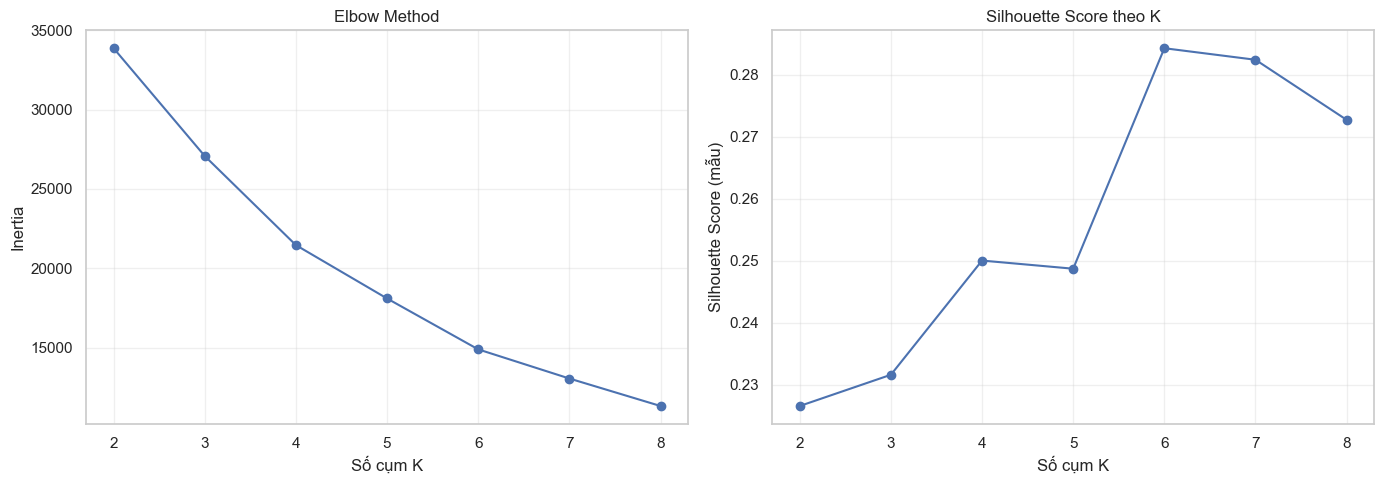

K được chọn theo Silhouette Score cao nhất: 6
Silhouette Score ước lượng: 0.2843
Lưu ý: đây là lựa chọn theo chỉ số định lượng; cần xem thêm biểu đồ và hồ sơ cụm trước khi kết luận nghiệp vụ.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(results_df["K"], results_df["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Số cụm K")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(results_df["K"])
axes[0].grid(alpha=0.3)

axes[1].plot(results_df["K"], results_df["Silhouette Score (sample)"], marker="o")
axes[1].set_title("Silhouette Score theo K")
axes[1].set_xlabel("Số cụm K")
axes[1].set_ylabel("Silhouette Score (mẫu)")
axes[1].set_xticks(results_df["K"])
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_k = int(results_df.loc[results_df["Silhouette Score (sample)"].idxmax(), "K"])
best_model = models[best_k]
print(f"K được chọn theo Silhouette Score cao nhất: {best_k}")
print(f"Silhouette Score ước lượng: {results_df.loc[results_df['K'] == best_k, 'Silhouette Score (sample)'].iloc[0]:.4f}")
print("Lưu ý: đây là lựa chọn theo chỉ số định lượng; cần xem thêm biểu đồ và hồ sơ cụm trước khi kết luận nghiệp vụ.")

## Step 7 — Huấn luyện mô hình cuối cùng và gán nhãn cụm

Sau khi chọn `K`, lấy mô hình tương ứng để gán một nhãn cụm cho mỗi khách hàng. Nhãn cụm được thêm vào bảng đã làm sạch. Không có cột `Cluster` ban đầu trong dữ liệu; đây là kết quả do thuật toán tạo ra.

Tâm cụm hiện nằm trong không gian đã chuẩn hóa. Để diễn giải trực quan hơn, ta chuyển các tâm về đơn vị gốc bằng công thức ngược: `x = z * std + mean`.

In [12]:
df_clustered = df.reset_index(drop=True).copy()
df_clustered["Cluster"] = best_model.predict(X)
centers_original = best_model.cluster_centers_ * stds.to_numpy() + means.to_numpy()
centers_df = pd.DataFrame(centers_original, columns=feature_cols)
centers_df.index.name = "Cluster"

print("Số cụm thực tế:", df_clustered["Cluster"].nunique())
print("Số khách hàng:", len(df_clustered))
print("Tâm cụm ở đơn vị gốc:")
display(centers_df.round(2))
print("Số lượng khách hàng theo cụm:")
display(df_clustered["Cluster"].value_counts().sort_index().rename("Customer count").to_frame())

Số cụm thực tế: 6
Số khách hàng: 15079
Tâm cụm ở đơn vị gốc:


,Age,Annual Income,Spending Score
Cluster,,,
0,63.66,60493.98,77.85
1,43.31,159895.22,23.27
2,34.16,137157.74,77.87
3,34.87,61800.60,35.63
4,73.89,157673.60,64.39
5,74.37,83663.86,23.74


Số lượng khách hàng theo cụm:


,Customer count
Cluster,
0,2491
1,2385
2,2482
3,2594
4,2609
5,2518


## Step 8 — Đánh giá và trực quan hóa kết quả

### 8.1. Hồ sơ cụm (Cluster Profiling)

Với từng cụm, tính số lượng khách hàng, giá trị trung bình và trung vị của tuổi, thu nhập, điểm chi tiêu. Tỷ lệ giới tính được tính riêng để hỗ trợ mô tả, không phải tiêu chí đã được dùng để tạo cụm.

**Cách đọc:** so sánh các cụm với nhau trên từng thuộc tính. Ví dụ, một cụm có thu nhập trung bình cao nhưng điểm chi tiêu thấp có thể gợi ý nhóm khách hàng có khả năng chi trả nhưng hiện chưa chi tiêu nhiều. Đây chỉ là gợi ý để doanh nghiệp kiểm chứng thêm, không phải kết luận nhân quả.

In [13]:
profile = df_clustered.groupby("Cluster")[feature_cols].agg(["count", "mean", "median"])
profile.columns = [f"{feature}_{stat}" for feature, stat in profile.columns]
gender_share = pd.crosstab(df_clustered["Cluster"], df_clustered["Gender"], normalize="index").mul(100).round(2)
gender_share.columns = [f"Gender_%_{col}" for col in gender_share.columns]
profile = profile.join(gender_share)
print("HỒ SƠ CÁC CỤM")
display(profile.round(2))

print("TỶ LỆ KHÁCH HÀNG THEO CỤM (%)")
cluster_percent = (df_clustered["Cluster"].value_counts(normalize=True).sort_index() * 100)
display(cluster_percent.rename("Percent").to_frame().round(2))

HỒ SƠ CÁC CỤM


,Age_count,Age_mean,Age_median,Annual Income_count,Annual Income_mean,Annual Income_median,Spending Score_count,Spending Score_mean,Spending Score_median,Gender_%_Female,Gender_%_Male
Cluster,,,,,,,,,,,
0,2491,63.66,64.0,2491,60493.98,58367.0,2491,77.85,79.0,49.70,50.30
1,2385,43.31,43.0,2385,159895.22,162849.0,2385,23.27,22.0,50.82,49.18
2,2482,34.16,33.0,2482,137157.74,138530.5,2482,77.87,79.0,49.44,50.56
3,2594,34.87,34.0,2594,61800.60,58726.5,2594,35.63,36.0,49.85,50.15
4,2609,73.89,75.0,2609,157673.60,159298.0,2609,64.39,64.0,48.26,51.74
5,2518,74.37,75.0,2518,83663.86,83131.0,2518,23.74,23.0,49.84,50.16


TỶ LỆ KHÁCH HÀNG THEO CỤM (%)


,Percent
Cluster,
0,16.52
1,15.82
2,16.46
3,17.20
4,17.30
5,16.70


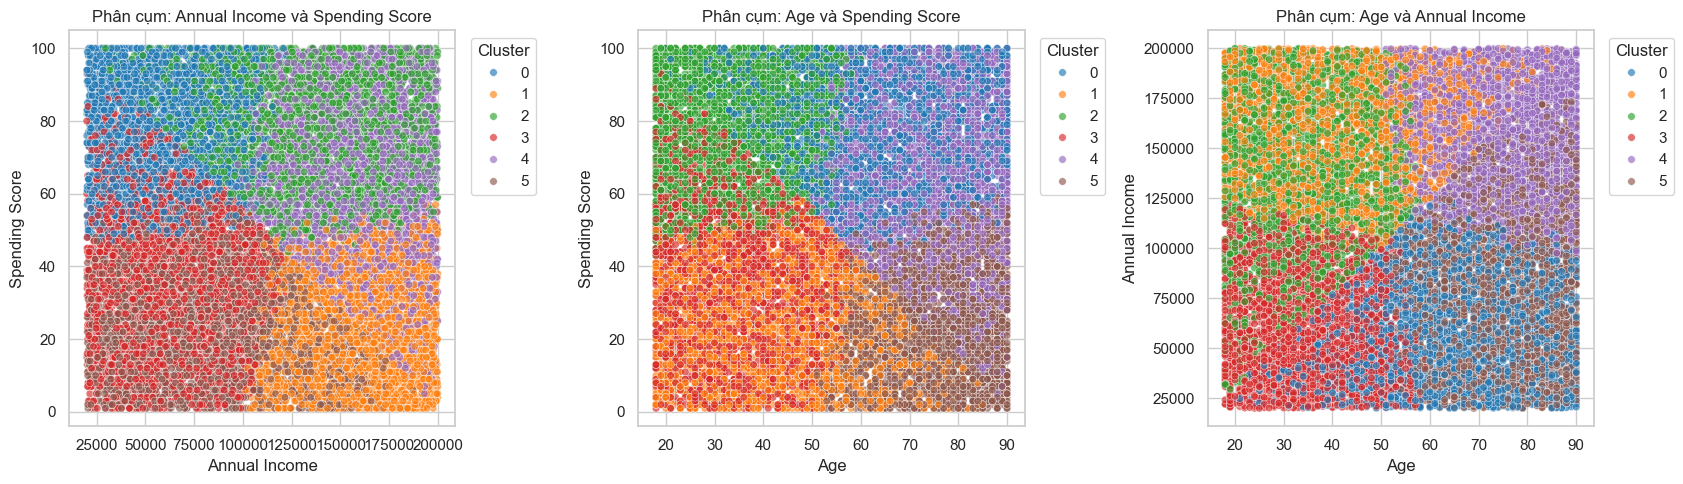

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (x_col, y_col) in zip(axes, [("Annual Income", "Spending Score"),
                                     ("Age", "Spending Score"),
                                     ("Age", "Annual Income")]):
    sns.scatterplot(data=df_clustered, x=x_col, y=y_col, hue="Cluster", palette="tab10",
                    alpha=0.65, s=30, ax=ax)
    ax.set_title(f"Phân cụm: {x_col} và {y_col}")
    ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

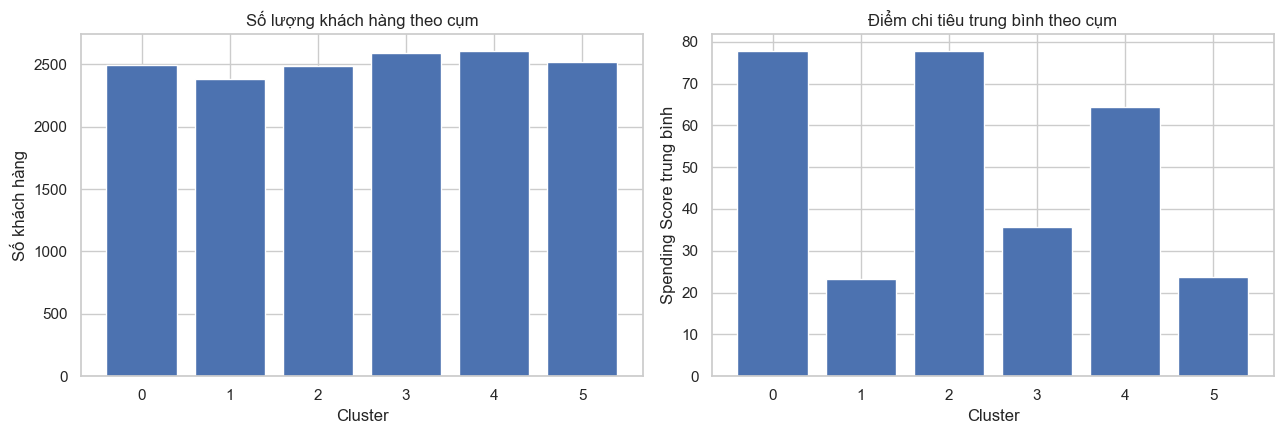

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cluster_counts = df_clustered["Cluster"].value_counts().sort_index()
axes[0].bar(cluster_counts.index.astype(str), cluster_counts.values)
axes[0].set_title("Số lượng khách hàng theo cụm")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Số khách hàng")

mean_spending = df_clustered.groupby("Cluster")["Spending Score"].mean().sort_index()
axes[1].bar(mean_spending.index.astype(str), mean_spending.values)
axes[1].set_title("Điểm chi tiêu trung bình theo cụm")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Spending Score trung bình")
plt.tight_layout()
plt.show()

### 8.2. Đánh giá tổng hợp

Không có một chỉ số duy nhất đủ để đánh giá mọi khía cạnh của phân cụm. Inertia luôn có xu hướng giảm khi tăng `K`; Silhouette hỗ trợ đo mức tách biệt nhưng cũng có thể thấp nếu dữ liệu chồng lấn hoặc hình dạng cụm không phù hợp với giả định của K-means. Vì vậy cần xem đồng thời:

1. Đồ thị Elbow — mức giảm Inertia khi tăng K.
2. Silhouette Score — độ tách biệt ước lượng.
3. Kích thước cụm — tránh cụm quá nhỏ hoặc mất cân bằng bất thường.
4. Hồ sơ cụm — các nhóm có ý nghĩa diễn giải và hữu ích cho bài toán hay không.

Kết quả tốt về mặt thuật toán chưa tự động đảm bảo chiến lược tiếp thị tốt; cần thêm kiến thức nghiệp vụ và đánh giá thực tế.

## Step 9 — Thử phân cụm một khách hàng mới

K-means không dự đoán một nhãn mục tiêu đã biết như bài toán phân loại. Với khách hàng mới, ta dùng **chính thông số chuẩn hóa đã tính ở Step 4**, sau đó gán khách hàng vào tâm cụm gần nhất.

Thay các giá trị ví dụ bên dưới bằng hồ sơ muốn thử. Các giá trị cần cùng đơn vị với dữ liệu gốc.

In [16]:
# Hồ sơ ví dụ; có thể chỉnh lại các giá trị này.
new_customer = pd.DataFrame([{
    "Age": 30,
    "Annual Income": 75000,
    "Spending Score": 65
}])

new_customer_scaled = (new_customer[feature_cols] - means) / stds
new_cluster = int(best_model.predict(new_customer_scaled.to_numpy(dtype=float))[0])
print("Hồ sơ khách hàng mới:")
display(new_customer)
print(f"Khách hàng mới được gán vào Cluster {new_cluster}.")
print("Đặc điểm trung bình của cụm này:")
display(profile.loc[[new_cluster]].round(2))

Hồ sơ khách hàng mới:


,Age,Annual Income,Spending Score
0,30,75000,65


Khách hàng mới được gán vào Cluster 3.
Đặc điểm trung bình của cụm này:


,Age_count,Age_mean,Age_median,Annual Income_count,Annual Income_mean,Annual Income_median,Spending Score_count,Spending Score_mean,Spending Score_median,Gender_%_Female,Gender_%_Male
Cluster,,,,,,,,,,,
3,2594,34.87,34.0,2594,61800.6,58726.5,2594,35.63,36.0,49.85,50.15


## Step 10 — Lưu kết quả thực nghiệm

Để có thể đưa kết quả vào báo cáo hoặc tiếp tục phân tích, ta lưu bảng dữ liệu có nhãn cụm, hồ sơ cụm và kết quả thử nghiệm. Các file được lưu trong thư mục `lab03_outputs` bên cạnh môi trường chạy notebook.

In [17]:
OUTPUT_DIR = Path("lab03_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_clustered.to_csv(OUTPUT_DIR / "customer_clusters.csv", index=False)
profile.to_csv(OUTPUT_DIR / "cluster_profile.csv")
results_df.to_csv(OUTPUT_DIR / "experiment_results.csv", index=False)
centers_df.to_csv(OUTPUT_DIR / "cluster_centers_original_scale.csv")

summary = {
    "customer_count": int(len(df_clustered)),
    "feature_columns": feature_cols,
    "selected_k_by_silhouette": int(best_k),
    "inertia": float(best_model.inertia_),
    "silhouette_score_sample": float(results_df.loc[results_df["K"] == best_k, "Silhouette Score (sample)"].iloc[0]),
    "cluster_sizes": {str(int(k)): int(v) for k, v in cluster_counts.items()},
}
summary_df = pd.DataFrame([{"Metric": key, "Value": str(value)} for key, value in summary.items()])
summary_df.to_csv(OUTPUT_DIR / "results_summary.csv", index=False)
print("Đã lưu các tệp:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.resolve())

Đã lưu các tệp:
- C:\ML\Lab03_ML\notebooks\lab03_outputs\cluster_centers_original_scale.csv
- C:\ML\Lab03_ML\notebooks\lab03_outputs\cluster_profile.csv
- C:\ML\Lab03_ML\notebooks\lab03_outputs\customer_clusters.csv
- C:\ML\Lab03_ML\notebooks\lab03_outputs\experiment_results.csv
- C:\ML\Lab03_ML\notebooks\lab03_outputs\results_summary.csv


## Step 11 — Tổng kết, giới hạn và hướng phát triển

### 11.1. Tổng kết

Trong notebook này, quy trình phân cụm được thực hiện đầy đủ từ kiểm tra dữ liệu, khám phá phân phối, làm sạch, chuẩn hóa, cài đặt K-means bằng NumPy, thử nhiều giá trị `K`, đánh giá bằng Inertia và Silhouette Score đến phân tích hồ sơ từng cụm. Kết quả được lưu thành các file CSV để sử dụng trong báo cáo.

### 11.2. Giới hạn

- K-means nhạy với tâm khởi tạo và có thể bị ảnh hưởng bởi ngoại lệ.
- K-means ưu tiên cụm dạng tương đối tròn trong không gian đặc trưng; nếu cụm có hình dạng phức tạp, thuật toán khác có thể phù hợp hơn.
- Silhouette trong notebook là ước lượng trên mẫu, nên có thể thay đổi nếu đổi mẫu hoặc seed.
- Nhãn `Cluster 0`, `Cluster 1`, ... là nhãn tùy ý. Không nên gán tên nhóm chỉ dựa trên số thứ tự.
- Các đặc trưng dùng để phân cụm chưa bao quát toàn bộ hành vi khách hàng; cần thêm dữ liệu giao dịch và xác thực ý nghĩa nghiệp vụ trước khi triển khai.

### 11.3. Hướng phát triển

- So sánh với K-means nhiều lần khởi tạo hoặc thuật toán phân cụm khác.
- Thử các tập đặc trưng khác nhau và đánh giá độ ổn định của cụm.
- Đặt tên nhóm theo hồ sơ thực tế, chẳng hạn dựa vào mức thu nhập và điểm chi tiêu, sau khi xem bảng `cluster_profile.csv`.
- Dùng kết quả phân cụm để đề xuất chiến lược chăm sóc khách hàng và đánh giá hiệu quả trên dữ liệu mới.

## Step 12 — So sánh không gian đặc trưng và Grid Search mở rộng

Phần này mở rộng thí nghiệm theo hướng so sánh 2D–5D. Mỗi không gian được chuẩn hóa độc lập. `Customer ID` không bao giờ được đưa vào mô hình. Không gian 5D có `Gender_encoded` chỉ mang tính khảo sát vì mã hóa nhị phân có thể tạo ra khoảng cách không tự nhiên; không mặc định rằng thêm biến sẽ làm mô hình tốt hơn.

Chạy cell từ thư mục gốc dự án hoặc thư mục `notebooks`. Kết quả chi tiết được lưu ở `data/processed/`.


In [18]:
# Chuẩn bị đường dẫn để notebook gọi lại đúng phần cài đặt trong src/.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src" / "experiments.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "experiments.py").exists():
    raise FileNotFoundError("Hãy mở notebook từ thư mục gốc Lab03_ML hoặc thư mục notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Ghi bộ dữ liệu sạch để các module thực nghiệm dùng chung một nguồn dữ liệu.
(PROJECT_ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
df.to_csv(PROJECT_ROOT / "data" / "processed" / "customers_clean.csv", index=False)

from src.experiments import make_feature_spaces, run_space_comparison, run_grid_search, plot_comparison

feature_spaces = make_feature_spaces(df)
space_results = run_space_comparison(feature_spaces)
plot_comparison(space_results)
print("So sánh các không gian đặc trưng:")
display(space_results.sort_values(["Feature_Space", "K"]).round(4))


So sánh các không gian đặc trưng:


,Feature_Space,Features,K,Inertia,Silhouette,Calinski_Harabasz,Davies_Bouldin,Iterations
0,2D_Core,"Annual Income, Spending Score",2,18907.6024,0.3697,8971.1133,1.1934,6
1,2D_Core,"Annual Income, Spending Score",3,11997.2115,0.3887,11410.6535,0.8711,32
2,2D_Core,"Annual Income, Spending Score",4,7548.6550,0.3955,15050.6229,0.7692,19
3,2D_Core,"Annual Income, Spending Score",5,6435.0802,0.3670,13892.5732,0.8899,40
4,2D_Core,"Annual Income, Spending Score",6,5474.7443,0.3417,13591.5284,0.9614,23
5,2D_Core,"Annual Income, Spending Score",7,4628.7024,0.3668,13854.7674,0.8470,36
6,2D_Core,"Annual Income, Spending Score",8,3888.9397,0.3743,14543.1122,0.7979,39
7,3D_Demographics,"Age, Annual Income, Spending Score",2,33875.6134,0.2265,5056.6059,1.6426,26
8,3D_Demographics,"Age, Annual Income, Spending Score",3,27077.7208,0.2316,5055.2499,1.3353,42
9,3D_Demographics,"Age, Annual Income, Spending Score",4,21458.9369,0.2500,5568.0656,1.1883,114


### 12.1. Grid Search tham số

Grid Search khảo sát `K`, cách khởi tạo (`random`, `k-means++`) và `max_iter` (60, 120), giữ `tol=1e-4`. Silhouette mẫu dùng để xếp hạng cấu hình; Calinski-Harabasz và Davies-Bouldin được báo cáo để đối chiếu. Đây là tìm kiếm trên phạm vi đã định, không khẳng định tìm được nghiệm tối ưu toàn cục.


In [19]:
grid_results = run_grid_search(feature_spaces)
best_by_space = (
    grid_results.sort_values("Silhouette", ascending=False)
    .groupby("Feature_Space", as_index=False)
    .first()
)
print("Cấu hình có Silhouette cao nhất trong từng không gian:")
display(best_by_space[["Feature_Space", "K", "Init", "Max_Iter", "Silhouette",
                       "Calinski_Harabasz", "Davies_Bouldin", "Inertia"]].round(4))


Cấu hình có Silhouette cao nhất trong từng không gian:


,Feature_Space,K,Init,Max_Iter,Silhouette,Calinski_Harabasz,Davies_Bouldin,Inertia
0,2D_Core,4,k-means++,120,0.3955,15050.6229,0.7692,7548.6550
1,3D_Demographics,6,random,60,0.2859,6134.2705,0.9563,14905.6510
2,3D_Ratio,3,k-means++,120,0.3973,11218.4118,0.9282,18180.2634


## Step 13 — Theo dõi quá trình hội tụ

Ngoài kết quả cuối cùng, cần quan sát Inertia và độ dịch chuyển của tâm qua từng vòng lặp. K-means dừng khi độ dịch chuyển tâm nhỏ hơn `tol` hoặc đạt `max_iter`. Lịch sử này giúp giải thích rõ hai bước Assignment và Update.


In [20]:
from src.models.kmeans import KMeans

# Dùng mẫu 1.200 điểm trong không gian 2D để demo trực quan, không thay kết quả chính.
X_demo = np.asarray(feature_spaces["2D_Core"]["X"], dtype=float)

rng_demo = np.random.default_rng(42)
idx_demo = rng_demo.choice(len(X_demo), size=min(1200, len(X_demo)), replace=False)

demo_model = KMeans(
    n_clusters=5, init="random", max_iter=100,
    tol=1e-4, random_state=42
).fit(X_demo[idx_demo])

convergence_df = pd.DataFrame([
    {
        "Iteration": h["iteration"],
        "Inertia": h["inertia"],
        "Centroid shift": h["centroid_shift"],
        "Cluster sizes": h["cluster_sizes"]
    }
    for h in demo_model.history_
])

display(convergence_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(convergence_df["Iteration"], convergence_df["Inertia"], marker="o")
axes[0].set(title="Inertia theo vòng lặp", xlabel="Iteration", ylabel="Inertia")

axes[1].plot(convergence_df["Iteration"], convergence_df["Centroid shift"], marker="o")
axes[1].set(title="Độ dịch chuyển tâm cụm", xlabel="Iteration", ylabel="Centroid shift")

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


,Iteration,Inertia,Centroid shift,Cluster sizes
0,1,580.042821,1.127011,"[270, 140, 271, 273, 246]"
1,2,547.843324,0.302059,"[280, 166, 264, 274, 216]"
2,3,537.271578,0.173321,"[283, 179, 246, 270, 222]"
3,4,530.714856,0.125244,"[286, 193, 236, 268, 217]"
4,5,526.560793,0.099665,"[288, 205, 223, 267, 217]"
5,6,523.016402,0.096223,"[284, 212, 212, 271, 221]"
6,7,519.868866,0.084771,"[280, 220, 201, 274, 225]"
7,8,517.293587,0.086093,"[278, 225, 194, 277, 226]"
8,9,516.540842,0.051011,"[276, 226, 191, 278, 229]"
9,10,516.332105,0.025056,"[275, 227, 190, 278, 230]"


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_13116\3730473150.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Step 14 — Cách kết luận khi so sánh mô hình

- Inertia thấp hơn không tự động có nghĩa là mô hình tốt hơn vì Inertia thường giảm khi tăng K.
- Silhouette cao hơn thường tốt hơn; Davies-Bouldin thấp hơn thường tốt hơn; Calinski-Harabasz cao hơn thường tốt hơn.
- Các chỉ số cần được đọc cùng nhau, cùng kích thước cụm và biểu đồ phân tán. Silhouette trong thí nghiệm này là ước lượng trên mẫu tối đa 1.000 điểm.
- Nếu 2D dễ diễn giải và có chỉ số gần tương đương 3D/4D, có thể ưu tiên 2D vì dễ truyền đạt cho nghiệp vụ.
- Không chọn 5D chỉ vì có nhiều đặc trưng; kiểm tra ảnh hưởng của Gender và Ratio trước khi giữ chúng.

Các bảng được lưu tại `data/processed/feature_space_comparison.csv` và `data/processed/grid_search_results.csv`.
